<a href="https://colab.research.google.com/github/isparshgirics24-glitch/AI-LAB/blob/main/Week9FOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First-Order Logic Statements:
  a. ∀x: food(x) -> likes(John, x)
  b. food(Apple) ^ food(vegetables)
  c. ∀x ∀y: eats(x, y) ^ ¬killed(x) -> food(y)
  d. eats(Anil, Peanuts) ^ alive(Anil)
  e. ∀x: eats(Anil, x) -> eats(Harry, x)
  f. ∀x: ¬killed(x) -> alive(x)
  g. ∀x: alive(x) -> ¬killed(x)
  h. likes(John, Peanuts)



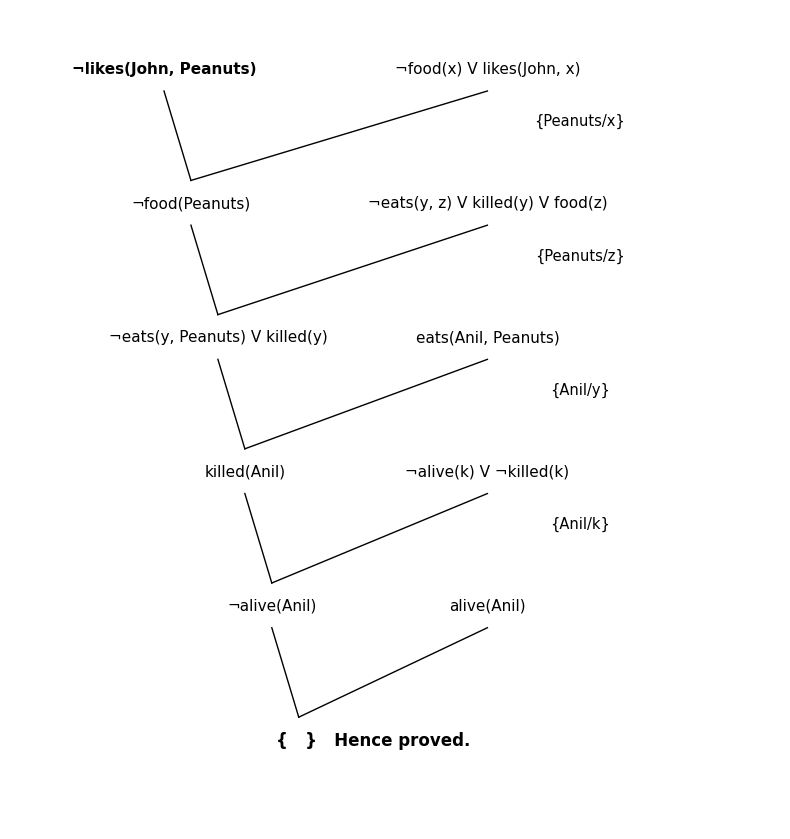

In [8]:
import matplotlib.pyplot as plt

def is_var(term):
    return len(term) == 1 and term.islower()

def unify_and_resolve(c1, c2):
    for l1 in c1:
        for l2 in c2:
            if l1.startswith('¬') != l2.startswith('¬'):
                p1, rest1 = l1.lstrip('¬').split('(')
                p2, rest2 = l2.lstrip('¬').split('(')
                if p1 == p2:
                    args1 = rest1[:-1].split(', ')
                    args2 = rest2[:-1].split(', ')
                    sub = {}
                    ok = True
                    for a, b in zip(args1, args2):
                        if a == b:
                            continue
                        elif is_var(a):
                            sub[a] = b
                        elif is_var(b):
                            sub[b] = a
                        else:
                            ok = False
                            break
                    if ok:
                        resolvent = []
                        for lit in c1 + c2:
                            if lit == l1 or lit == l2:
                                continue
                            for var, val in sub.items():
                                lit = lit.replace(f"({var},", f"({val},")
                                lit = lit.replace(f", {var})", f", {val})")
                                lit = lit.replace(f"({var})", f"({val})")
                            resolvent.append(lit)
                        return resolvent, sub
    return None, None


# First-Order Logic statements
fol_statements = [
    "a. ∀x: food(x) -> likes(John, x)",
    "b. food(Apple) ^ food(vegetables)",
    "c. ∀x ∀y: eats(x, y) ^ ¬killed(x) -> food(y)",
    "d. eats(Anil, Peanuts) ^ alive(Anil)",
    "e. ∀x: eats(Anil, x) -> eats(Harry, x)",
    "f. ∀x: ¬killed(x) -> alive(x)",
    "g. ∀x: alive(x) -> ¬killed(x)",
    "h. likes(John, Peanuts)"
]

# CNF Clauses
kb = [
    ["¬food(x)", "likes(John, x)"],
    ["food(Apple)"],
    ["food(vegetables)"],
    ["¬eats(y, z)", "killed(y)", "food(z)"],
    ["eats(Anil, Peanuts)"],
    ["alive(Anil)"],
    ["¬eats(Anil, w)", "eats(Harry, w)"],
    ["killed(v)", "alive(v)"],
    ["¬alive(k)", "¬killed(k)"]
]

goal = ["¬likes(John, Peanuts)"]

print("First-Order Logic Statements:")
for stmt in fol_statements:
    print(" ", stmt)
print()

# Run resolution
current = goal
steps = []
while current:
    matched = False
    for clause in kb:
        res, sub = unify_and_resolve(current, clause)
        if res is not None:
            steps.append((current, clause, sub, res))
            current = res
            matched = True
            break
    if not matched:
        break

# Draw the exact 5-step Proof Tree Graph
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.axis('off')
ax.set_xlim(0, 10)
ax.set_ylim(0, 11)

y = 10.2
left_x = 2.0
right_x = 6.2

for idx, (left, right, sub, result) in enumerate(steps):
    left_str = " V ".join(left)
    right_str = " V ".join(right)
    sub_str = "{" + ", ".join(f"{val}/{var}" for var, val in sub.items()) + "}" if sub else ""

    weight = 'bold' if idx == 0 else 'normal'
    ax.text(left_x, y, left_str, fontsize=11, fontweight=weight, ha='center', va='center')
    ax.text(right_x, y, right_str, fontsize=11, ha='center', va='center')

    if sub_str:
        ax.text(right_x + 1.2, y - 0.7, sub_str, fontsize=10.5, ha='center', va='center')

    next_y = y - 1.8
    next_left_x = left_x + 0.35

    ax.plot([left_x, next_left_x], [y - 0.3, next_y + 0.3], color='black', linewidth=1)
    ax.plot([right_x, next_left_x], [y - 0.3, next_y + 0.3], color='black', linewidth=1)

    y = next_y
    left_x = next_left_x

ax.text(left_x - 0.3, y, "{   }   Hence proved.", fontsize=12, fontweight='bold', ha='left', va='center')

plt.tight_layout()
plt.show()
